# GD, SGD, mini-batch

Ici, la loss complete est une fonction des parametres du modele.

$$
J : \mathbb{R}^p \to \mathbb{R}
$$

Sa dimension naturelle est donc `p + 1` si on compte la hauteur `J`.

- si `p = 2`, on peut visualiser une surface 3D : `(w, b, J(w,b))`
- si `p > 2`, la 3D n'est qu'une coupe ou une projection

Pour garder une visualisation propre, on prend ici un neurone avec une seule feature, donc deux parametres visibles : `w` et `b`.


**But** : charger les outils de calcul, d'affichage et le code du projet.

**Pourquoi** : garantir que le notebook visualise l'implementation reelle, pas une logique dupliquee.


In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

ROOT = Path.cwd().resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.activations.sigmoid import sigmoid
from src.layers.single_neuron import SingleNeuron, dataset_cost, predict_proba
from src.optim.sgd import SGD
from src.training.single_neuron import run_single_neuron_training

plt.style.use("default")
np.set_printoptions(precision=4, suppress=True)


**But** : construire un probleme binaire 1D simple.

**Pourquoi** : garder seulement `w` et `b` visibles pour lire clairement la loss et la recherche du minimum.


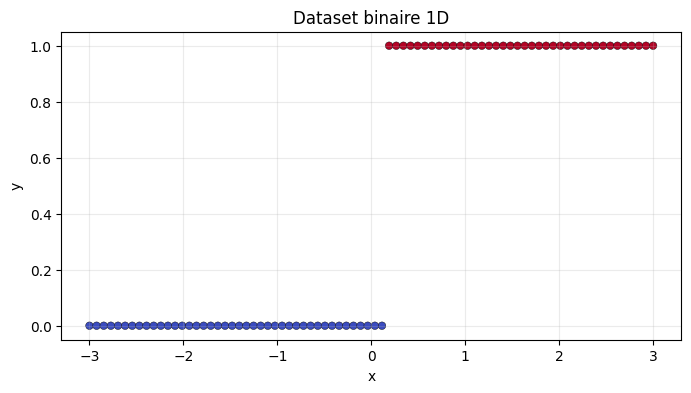

In [5]:
X = np.linspace(-3.0, 3.0, 80).reshape(-1, 1)
logits = 2.2 * X[:, 0] - 0.4
probas = sigmoid(logits)
y = (probas > 0.5).astype(float)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X[:, 0], y, c=y, cmap="coolwarm", s=30, edgecolor="black", linewidth=0.3)
ax.set_title("Dataset binaire 1D")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.25)
plt.show()


**But** : lancer `GD`, `SGD` et `mini-batch` depuis le module d'entraînement.

**Pourquoi** : comparer uniquement l'effet de la taille de batch sur le chemin d'optimisation.


In [6]:
initial_model = SingleNeuron(w=np.array([-2.5]), b=2.0)

gd_history = run_single_neuron_training(
    X,
    y,
    model=initial_model,
    optimizer=SGD(lr=0.8),
    epochs=25,
    batch_size=len(X),
    shuffle=False,
    seed=0,
)

sgd_history = run_single_neuron_training(
    X,
    y,
    model=initial_model,
    optimizer=SGD(lr=0.08),
    epochs=25,
    batch_size=1,
    shuffle=True,
    seed=0,
)

mini_history = run_single_neuron_training(
    X,
    y,
    model=initial_model,
    optimizer=SGD(lr=0.25),
    epochs=25,
    batch_size=8,
    shuffle=True,
    seed=0,
)


**But** : calculer la surface `J(w,b)`.

**Pourquoi** : voir la vallee que chaque methode essaie de descendre.


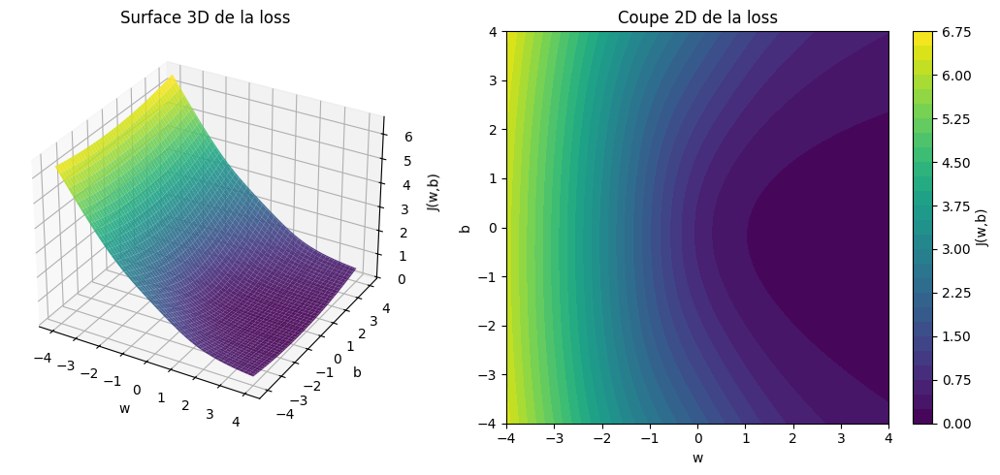

In [7]:
w_grid = np.linspace(-4.0, 4.0, 140)
b_grid = np.linspace(-4.0, 4.0, 140)
W, B = np.meshgrid(w_grid, b_grid)
J = np.zeros_like(W)

for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        J[i, j] = dataset_cost(X, y, np.array([W[i, j]]), float(B[i, j]))

fig = plt.figure(figsize=(11, 5))
ax1 = fig.add_subplot(121, projection="3d")
ax1.plot_surface(W, B, J, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
ax1.set_title("Surface 3D de la loss")
ax1.set_xlabel("w")
ax1.set_ylabel("b")
ax1.set_zlabel("J(w,b)")

ax2 = fig.add_subplot(122)
contours = ax2.contourf(W, B, J, levels=30, cmap="viridis")
fig.colorbar(contours, ax=ax2, label="J(w,b)")
ax2.set_title("Coupe 2D de la loss")
ax2.set_xlabel("w")
ax2.set_ylabel("b")
plt.tight_layout()
plt.show()


**But** : projeter les trajectoires des parametres sur les courbes de niveau.

**Pourquoi** : distinguer une descente lisse, une descente bruitee et un compromis mini-batch.


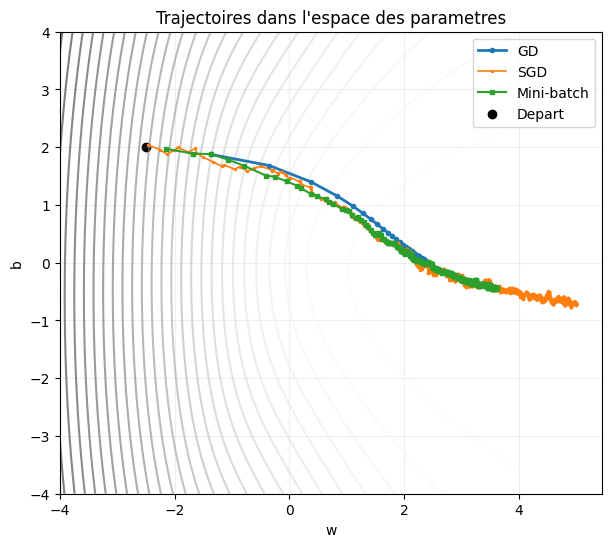

In [8]:
def unpack(history):
    return np.array([step.w for step in history]), np.array([step.b for step in history]), np.array([step.loss for step in history])

gd_w, gd_b, gd_loss = unpack(gd_history)
sgd_w, sgd_b, sgd_loss = unpack(sgd_history)
mini_w, mini_b, mini_loss = unpack(mini_history)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contour(W, B, J, levels=25, cmap="Greys", alpha=0.55)
ax.plot(gd_w, gd_b, marker="o", markersize=3, linewidth=2, label="GD")
ax.plot(sgd_w, sgd_b, marker=".", markersize=3, linewidth=1.2, label="SGD")
ax.plot(mini_w, mini_b, marker="s", markersize=2.5, linewidth=1.5, label="Mini-batch")
ax.scatter([-2.5], [2.0], color="black", label="Depart")
ax.set_title("Trajectoires dans l'espace des parametres")
ax.set_xlabel("w")
ax.set_ylabel("b")
ax.legend()
ax.grid(True, alpha=0.2)
plt.show()


**But** : animer la recherche du minimum update par update.

**Pourquoi** : voir concretement comment `GD`, `SGD` et `mini-batch` explorent la vallee.


In [9]:
max_steps = max(len(gd_history), len(sgd_history), len(mini_history))
frame_count = min(120, max_steps)
frame_indices = np.unique(np.linspace(0, max_steps - 1, frame_count, dtype=int))

fig, ax = plt.subplots(figsize=(7, 6))
ax.contour(W, B, J, levels=25, cmap="Greys", alpha=0.55)
ax.set_title("Animation des trajectoires dans la vallee")
ax.set_xlabel("w")
ax.set_ylabel("b")
ax.grid(True, alpha=0.2)

gd_line, = ax.plot([], [], color="tab:blue", linewidth=2, label="GD")
sgd_line, = ax.plot([], [], color="tab:orange", linewidth=1.2, label="SGD")
mini_line, = ax.plot([], [], color="tab:green", linewidth=1.5, label="Mini-batch")
gd_point, = ax.plot([], [], marker="o", color="tab:blue")
sgd_point, = ax.plot([], [], marker="o", color="tab:orange")
mini_point, = ax.plot([], [], marker="o", color="tab:green")
ax.scatter([-2.5], [2.0], color="black", s=30, label="Depart")
ax.legend()

def _slice(values, index):
    stop = min(index + 1, len(values))
    return values[:stop]

def update(frame):
    step = int(frame_indices[frame])
    gd_line.set_data(_slice(gd_w, step), _slice(gd_b, step))
    sgd_line.set_data(_slice(sgd_w, step), _slice(sgd_b, step))
    mini_line.set_data(_slice(mini_w, step), _slice(mini_b, step))

    gd_idx = min(step, len(gd_w) - 1)
    sgd_idx = min(step, len(sgd_w) - 1)
    mini_idx = min(step, len(mini_w) - 1)

    gd_point.set_data([gd_w[gd_idx]], [gd_b[gd_idx]])
    sgd_point.set_data([sgd_w[sgd_idx]], [sgd_b[sgd_idx]])
    mini_point.set_data([mini_w[mini_idx]], [mini_b[mini_idx]])
    return gd_line, sgd_line, mini_line, gd_point, sgd_point, mini_point

animation = FuncAnimation(fig, update, frames=len(frame_indices), interval=120, blit=True, repeat=True)
plt.close(fig)
HTML(animation.to_jshtml())


**But** : tracer la loss et la norme du gradient au fil des updates.

**Pourquoi** : mesurer vitesse, bruit et stabilite de chaque methode.


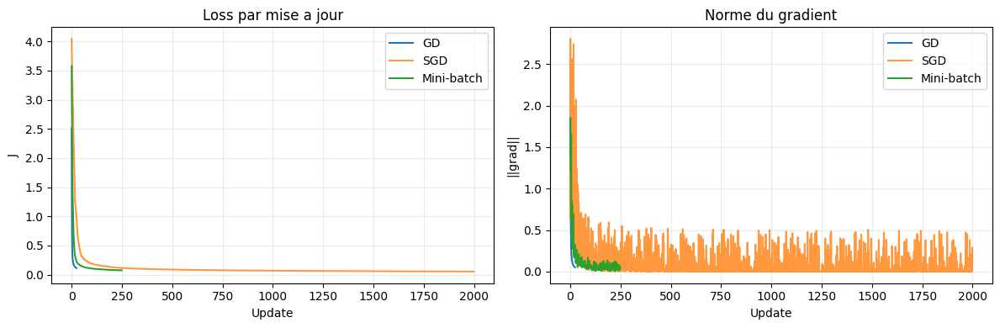

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(gd_loss, label="GD")
axes[0].plot(sgd_loss, label="SGD", alpha=0.8)
axes[0].plot(mini_loss, label="Mini-batch")
axes[0].set_title("Loss par mise a jour")
axes[0].set_xlabel("Update")
axes[0].set_ylabel("J")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].plot([step.grad_norm for step in gd_history], label="GD")
axes[1].plot([step.grad_norm for step in sgd_history], label="SGD", alpha=0.8)
axes[1].plot([step.grad_norm for step in mini_history], label="Mini-batch")
axes[1].set_title("Norme du gradient")
axes[1].set_xlabel("Update")
axes[1].set_ylabel("||grad||")
axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


**But** : visualiser la courbe de probabilite apprise.

**Pourquoi** : relier le mouvement dans l'espace des parametres a la prediction finale du neurone.


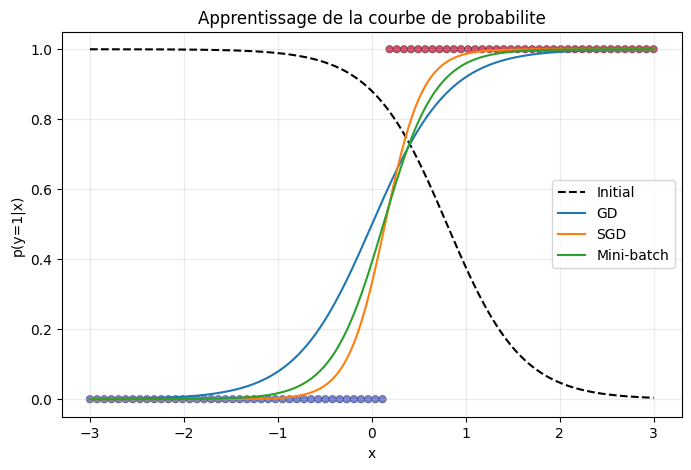

In [8]:
x_line = np.linspace(-3.0, 3.0, 300)

def curve(history):
    weight = history[-1].w
    bias = history[-1].b
    return np.array([predict_proba(np.array([x_value]), np.array([weight]), bias) for x_value in x_line])

start_curve = np.array([predict_proba(np.array([x_value]), np.array([-2.5]), 2.0) for x_value in x_line])
gd_curve = curve(gd_history)
sgd_curve = curve(sgd_history)
mini_curve = curve(mini_history)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[:, 0], y, c=y, cmap="coolwarm", s=30, alpha=0.7, edgecolor="black", linewidth=0.3)
ax.plot(x_line, start_curve, label="Initial", linestyle="--", color="black")
ax.plot(x_line, gd_curve, label="GD")
ax.plot(x_line, sgd_curve, label="SGD")
ax.plot(x_line, mini_curve, label="Mini-batch")
ax.set_title("Apprentissage de la courbe de probabilite")
ax.set_xlabel("x")
ax.set_ylabel("p(y=1|x)")
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()
